# 11 — Concept analysis: filtro neuroni validi, statistiche e visualizzazioni

Notebook di analisi delle attivazioni SAE sul **test set**, prodotte dal notebook 10.

**Cosa fa**:
1. Carica le attivazioni SAE `[N_test, 6144]` (memmap float32) e la concept map adattiva.
2. Filtra i neuroni `valid=True` e restringe la matrice alle sole colonne valide.
3. Calcola la distribuzione del numero di concetti attivi per immagine (istogramma skewed).
4. Calcola la frequenza dei concetti nel dataset e salva una tabella riassuntiva.
5. Mostra 8 immagini campione (varieta' high/low concetti + random) con i top-5 concetti attivi.



## 1. Setup Colab — Drive e dipendenze

Monta Google Drive con `force_remount=True` per garantire che eventuali file caricati su Drive dopo un mount precedente siano effettivamente visibili (Colab fa cache aggressiva del mount). Non e' necessario clonare la repo MSAE: questo notebook usa solo numpy/pandas/PIL/matplotlib (preinstallati su Colab).

In [2]:
import os
import sys
import zipfile
import pathlib

from google.colab import drive

# force_remount=True: invalida la cache di Colab e ri-monta Drive. Necessario quando
# file sono stati caricati su Drive dopo un mount precedente: senza remount, Colab
# vede uno snapshot stale e os.path.exists() ritorna False anche se il file esiste.
drive.mount('/content/drive', force_remount=True)

# Decomprime il subset di immagini in locale se non gia' presente (necessario per la cella 6).
# Stesso pattern del notebook 6: estrae output_subset.zip da Drive in /content/tesi/.
SUBSET_LOCAL = pathlib.Path('/content/tesi/output_subset')
ZIP_ON_DRIVE = pathlib.Path('/content/drive/MyDrive/tesi/output_subset.zip')

if not SUBSET_LOCAL.exists() and ZIP_ON_DRIVE.exists():
    print(f'Estrazione di {ZIP_ON_DRIVE.name} -> /content/tesi/ ...')
    SUBSET_LOCAL.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_ON_DRIVE, 'r') as z:
        z.extractall(SUBSET_LOCAL.parent)
    print('Estrazione completata.')
elif SUBSET_LOCAL.exists():
    print(f"output_subset gia' presente: {SUBSET_LOCAL}")
else:
    print(f'WARNING: ne {SUBSET_LOCAL} ne {ZIP_ON_DRIVE} esistono.')
    print("La cella 6 (visualizzazioni) fallira' nel caricamento immagini.")

Mounted at /content/drive
Estrazione di output_subset.zip -> /content/tesi/ ...
Estrazione completata.


## 2. Configurazione path

Tutte le path configurabili sono in cima. Nessun path hardcoded altrove.

Il file `image_paths_test.csv` mappa `embedding_idx -> path locale Colab dell'immagine`. Se non esiste, viene creato dinamicamente da `clip_image_embedding_manifest_test.csv` (prodotto dal notebook 6) convertendo i path Windows in path Colab — stessa logica `to_colab_path` del notebook 6.

In [ ]:
import pandas as pd

DRIVE_ROOT = '/content/drive/MyDrive/tesi'

# Attivazioni SAE sul test set (memmap float32, shape [N_TEST, 6144]).
SAE_ACTIVATIONS_PATH = f'{DRIVE_ROOT}/sae_activations_test_2938_6144.npy'
N_TEST = 2938
N_LATENTS = 6144

# Concept map adattiva (output del notebook 9).
CONCEPT_MAP_PATH = f'{DRIVE_ROOT}/concept_map_adaptive.csv'

# Manifest del test set (output del notebook 6).
TEST_MANIFEST_PATH = f'{DRIVE_ROOT}/clip_image_embedding_manifest_test.csv'

# Mapping embedding_idx -> path Colab dell'immagine. Creato al volo se assente.
IMAGE_PATHS_FILE = f'{DRIVE_ROOT}/image_paths_test.csv'

# Root locale Colab dove sono estratte le immagini del subset.
SUBSET_ROOT_LOCAL = '/content/tesi'

OUTPUT_DIR = f'{DRIVE_ROOT}'
CHARTS_DIR = f'{OUTPUT_DIR}/charts'
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CHARTS_DIR, exist_ok=True)

# --- Verifica file con diagnostica chiara su miss ---
# Se un file e' attualmente caricato su Drive ma os.path.exists() ritorna False, e' quasi
# sempre cache stale del mount: la cella 2 forza il remount, quindi a questo punto Drive
# dovrebbe essere coerente. Se assertion fallisce, listo la dir per evidenziare il mismatch.
required_files = {
    'SAE_ACTIVATIONS_PATH': SAE_ACTIVATIONS_PATH,
    'CONCEPT_MAP_PATH'    : CONCEPT_MAP_PATH,
    'TEST_MANIFEST_PATH'  : TEST_MANIFEST_PATH,
}
missing = {k: v for k, v in required_files.items() if not os.path.exists(v)}

if missing:
    print('=== ERRORE: file mancanti ===')
    for k, v in missing.items():
        print(f'  {k}: {v}')
    print(f'Contenuto effettivo di {OUTPUT_DIR}:')
    if os.path.isdir(OUTPUT_DIR):
        for name in sorted(os.listdir(OUTPUT_DIR)):
            full = os.path.join(OUTPUT_DIR, name)
            size = os.path.getsize(full) if os.path.isfile(full) else 0
            kind = 'DIR ' if os.path.isdir(full) else 'FILE'
            print(f'  [{kind}] {name}  ({size/1e6:.1f} MB)' if kind == 'FILE' else f'  [{kind}] {name}')
    else:
        print(f'  (la directory {OUTPUT_DIR} non esiste)')
    raise FileNotFoundError(
        f'File mancanti su Drive: {list(missing.keys())}. '
        'Se i file esistono su Drive ma non sono visibili qui, esegui di nuovo la cella 2 '
        '(force_remount=True) o riavvia il runtime.'
    )

# --- Creazione mapping embedding_idx -> path Colab immagine ---
if not os.path.exists(IMAGE_PATHS_FILE):
    print(f'{IMAGE_PATHS_FILE} non esiste, lo creo da {TEST_MANIFEST_PATH}.')
    df_manifest = pd.read_csv(TEST_MANIFEST_PATH)

    def to_colab_path(win_path: str) -> str:
        # Conversione coerente con notebook 6.
        p_str = win_path.replace('/', '\\')
        parts = p_str.split('\\')
        try:
            idx = parts.index('output_subset')
            tail = '\\'.join(parts[idx:])
            return os.path.join(SUBSET_ROOT_LOCAL, tail)
        except ValueError:
            return os.path.join(SUBSET_ROOT_LOCAL, parts[-1])

    df_manifest = df_manifest.sort_values('embedding_idx').reset_index(drop=True)
    df_manifest['image_path_colab'] = df_manifest['image_path_dest'].apply(to_colab_path)
    df_paths = df_manifest[['embedding_idx', 'cluster_id', 'category', 'image_path_colab']]
    df_paths.to_csv(IMAGE_PATHS_FILE, index=False)
    print(f'Salvato: {IMAGE_PATHS_FILE}  ({len(df_paths)} righe)')
else:
    print(f"Mapping immagini gia' presente: {IMAGE_PATHS_FILE}")

print(f'SAE_ACTIVATIONS_PATH : {SAE_ACTIVATIONS_PATH}')
print(f'CONCEPT_MAP_PATH     : {CONCEPT_MAP_PATH}')
print(f'IMAGE_PATHS_FILE     : {IMAGE_PATHS_FILE}')
print(f'CHARTS_DIR           : {CHARTS_DIR}')
print(f'OUTPUT_DIR           : {OUTPUT_DIR}')

=== ERRORE: file mancanti ===
  TEST_MANIFEST_PATH: /content/drive/MyDrive/tesi/outputs/clip_image_embedding_manifest_test.csv
Contenuto effettivo di /content/drive/MyDrive/tesi/outputs:
  [DIR ] charts
  [FILE] concept_map.csv  (0.3 MB)
  [FILE] concept_map_adaptive.csv  (0.3 MB)
  [FILE] concept_map_paper.csv  (0.3 MB)
  [FILE] laion_unigram_ViT-L~14_text_37445.txt  (0.3 MB)
  [FILE] laion_unigram_ViT-L~14_text_37445_768.npy  (115.0 MB)
  [FILE] sae_activations_test_2938_6144.npy  (72.2 MB)
  [FILE] similarity_matrix.npy  (920.2 MB)


FileNotFoundError: File mancanti su Drive: ['TEST_MANIFEST_PATH']. Se i file esistono su Drive ma non sono visibili qui, esegui di nuovo la cella 2 (force_remount=True) o riavvia il runtime.

## 3. Filtro ai neuroni validi

Carico la concept map e seleziono i neuroni con `valid=True`. Restringo la matrice attivazioni alle sole colonne dei neuroni validi: tutte le analisi a valle lavorano su `[N_TEST, N_valid]`.

In [6]:
import numpy as np

# Attivazioni come memmap read-only (non satura RAM Colab).
activations = np.memmap(SAE_ACTIVATIONS_PATH, dtype=np.float32, mode='r', shape=(N_TEST, N_LATENTS))

concept_map = pd.read_csv(CONCEPT_MAP_PATH)
valid_mask = concept_map['valid'].astype(bool).values
valid_neuron_ids = concept_map.loc[valid_mask, 'neuron_id'].values.astype(int)
valid_concepts = concept_map.loc[valid_mask, 'concept'].values.astype(str)

# Estrae solo le colonne dei neuroni validi -> [N_TEST, N_valid] in RAM (piccolo).
activations_valid = np.asarray(activations[:, valid_neuron_ids], dtype=np.float32)
n_valid = int(valid_mask.sum())

print(f'Neuroni totali         : {N_LATENTS}')
print(f'Neuroni validi         : {n_valid}')
print(f'Matrice filtrata shape : {list(activations_valid.shape)}')
print(f'Concetti validi        : {list(valid_concepts)}')

Neuroni totali         : 6144
Neuroni validi         : 26
Matrice filtrata shape : [2938, 26]
Concetti validi        : [np.str_('instaweather'), np.str_('manatee'), np.str_('donegal'), np.str_('windmill'), np.str_('galway'), np.str_('tampa'), np.str_('conwy'), np.str_('pink'), np.str_('aruba'), np.str_('marseille'), np.str_('bendigo'), np.str_('window'), np.str_('fuji'), np.str_('barns'), np.str_('instaweather'), np.str_('quito'), np.str_('blackandwhitephotography'), np.str_('kyoto'), np.str_('strasbourg'), np.str_('manatee'), np.str_('bed'), np.str_('cafeteria'), np.str_('wexmondays'), np.str_('andon'), np.str_('penang'), np.str_('guangzhou')]


## 4. Distribuzione del numero di concetti per immagine

Per ogni immagine del test set conto quanti neuroni validi hanno attivazione `> 0`. Mi aspetto una distribuzione **skewed**: la sparsity media del MSAE TopK-64 fa si' che ogni immagine abbia attivi solo pochi neuroni, e tra questi soltanto una frazione e' tra i validi. Tipicamente: molte immagini con 0–2 concetti, coda lunga verso valori piu' alti.

Media concetti attivi per immagine     : 12.14
Mediana concetti attivi per immagine   : 12.0
% immagini con 0 concetti attivi       : 0.03%
% immagini con > 5 concetti attivi     : 92.04%
Min / Max concetti per immagine        : 0 / 23


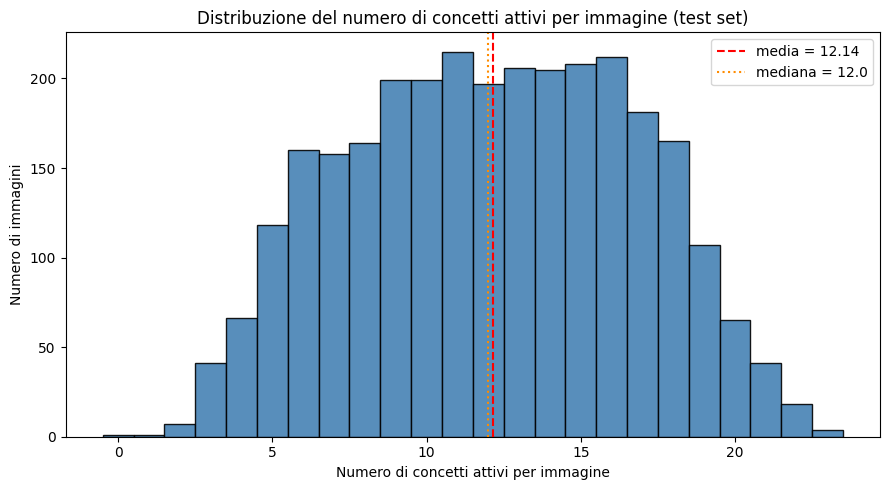


Grafico salvato: /content/drive/MyDrive/tesi/outputs/charts/plot_concepts_per_image.png


In [7]:
import matplotlib.pyplot as plt

concepts_per_image = (activations_valid > 0).sum(axis=1).astype(int)

mean_concepts = float(concepts_per_image.mean())
median_concepts = float(np.median(concepts_per_image))
pct_zero = 100.0 * float((concepts_per_image == 0).mean())
pct_gt5 = 100.0 * float((concepts_per_image > 5).mean())

print(f'Media concetti attivi per immagine     : {mean_concepts:.2f}')
print(f'Mediana concetti attivi per immagine   : {median_concepts:.1f}')
print(f'% immagini con 0 concetti attivi       : {pct_zero:.2f}%')
print(f'% immagini con > 5 concetti attivi     : {pct_gt5:.2f}%')
print(f'Min / Max concetti per immagine        : {concepts_per_image.min()} / {concepts_per_image.max()}')

max_c = int(concepts_per_image.max())
bins = np.arange(0, max_c + 2) - 0.5

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(concepts_per_image, bins=bins, color='steelblue', edgecolor='black', alpha=0.9)
ax.axvline(mean_concepts, color='red', linestyle='--', label=f'media = {mean_concepts:.2f}')
ax.axvline(median_concepts, color='darkorange', linestyle=':', label=f'mediana = {median_concepts:.1f}')
ax.set_xlabel('Numero di concetti attivi per immagine')
ax.set_ylabel('Numero di immagini')
ax.set_title('Distribuzione del numero di concetti attivi per immagine (test set)')
ax.legend()
fig.tight_layout()

out_path = os.path.join(CHARTS_DIR, 'plot_concepts_per_image.png')
fig.savefig(out_path, dpi=150)
plt.show()
print(f'\nGrafico salvato: {out_path}')

## 5. Frequenza dei concetti nel dataset

Per ogni concetto valido conto:
- in **quante immagini** si attiva (attivazione `> 0`),
- la **percentuale** di immagini coperte,
- la **magnitudo media** dell'attivazione quando il concetto e' attivo (informa su quanto "forte" e' il concetto, non solo su quanto e' frequente).

Salvo il bar chart dei top-20 in `CHARTS_DIR` e la tabella completa ordinata per frequenza in `OUTPUT_DIR/concept_stats.csv`.

Tabella salvata: /content/drive/MyDrive/tesi/outputs/concept_stats.csv

Prime 10 righe:
                 concept  neuron_id  n_images_active  pct_images_active  mean_activation_when_active
blackandwhitephotography       4225             1616              55.00                       0.6149
            instaweather       3895             1582              53.85                       1.7180
               guangzhou       6080             1529              52.04                       0.5841
              wexmondays       5142             1521              51.77                       1.0672
               marseille       3314             1507              51.29                       0.5747
                 donegal       1450             1503              51.16                       0.8498
              strasbourg       4498             1499              51.02                       1.1864
                   kyoto       4409             1480              50.37                       0.6144
   

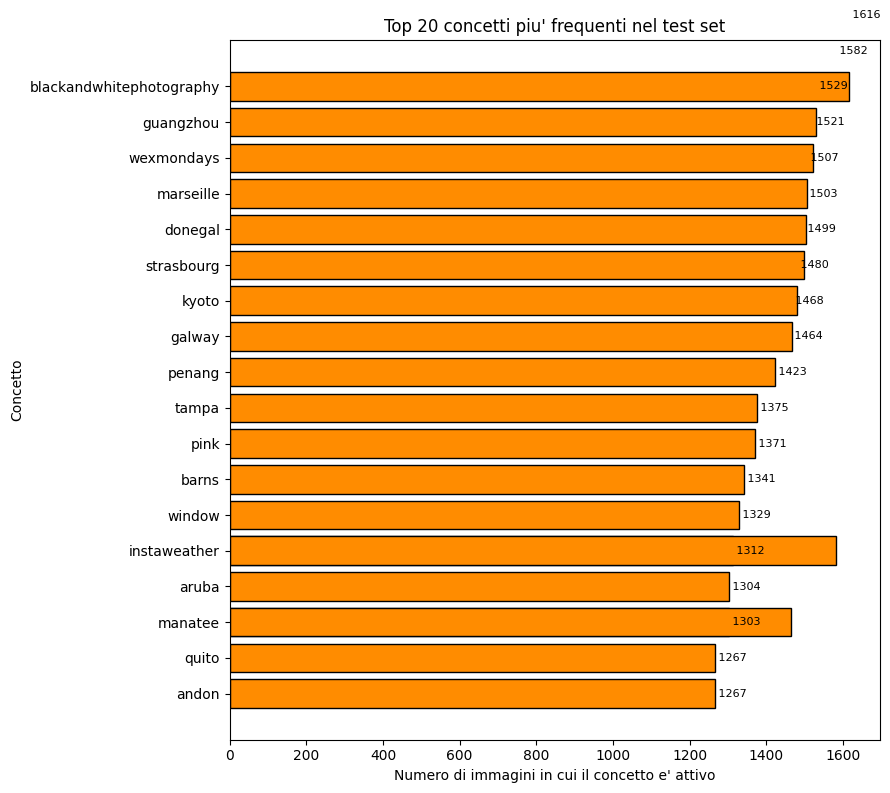


Grafico salvato: /content/drive/MyDrive/tesi/outputs/charts/plot_top20_concept_frequency.png


In [8]:
active_mask = activations_valid > 0  # [N_TEST, N_valid]
n_images_active = active_mask.sum(axis=0).astype(int)
pct_images_active = 100.0 * n_images_active / N_TEST

# Mean activation when active: somma sulle immagini in cui il neurone e' attivo,
# diviso il conteggio (evitando divisione per zero per i neuroni mai attivi).
sum_when_active = (activations_valid * active_mask).sum(axis=0)
with np.errstate(divide='ignore', invalid='ignore'):
    mean_activation_when_active = np.where(
        n_images_active > 0,
        sum_when_active / np.maximum(n_images_active, 1),
        0.0,
    ).astype(np.float32)

concept_stats = pd.DataFrame({
    'concept': valid_concepts,
    'neuron_id': valid_neuron_ids,
    'n_images_active': n_images_active,
    'pct_images_active': pct_images_active.round(2),
    'mean_activation_when_active': mean_activation_when_active.round(4),
}).sort_values('n_images_active', ascending=False).reset_index(drop=True)

stats_path = os.path.join(OUTPUT_DIR, 'concept_stats.csv')
concept_stats.to_csv(stats_path, index=False)
print(f'Tabella salvata: {stats_path}')
print(f'\nPrime 10 righe:')
print(concept_stats.head(10).to_string(index=False))

top20 = concept_stats.head(20).iloc[::-1]  # invertito per avere il piu' frequente in alto nel barh

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top20['concept'], top20['n_images_active'], color='darkorange', edgecolor='black')
ax.set_xlabel('Numero di immagini in cui il concetto e\' attivo')
ax.set_ylabel('Concetto')
ax.set_title('Top 20 concetti piu\' frequenti nel test set')
for i, (n, c) in enumerate(zip(top20['n_images_active'], top20['concept'])):
    ax.text(n, i, f' {n}', va='center', fontsize=8)
fig.tight_layout()

out_path = os.path.join(CHARTS_DIR, 'plot_top20_concept_frequency.png')
fig.savefig(out_path, dpi=150)
plt.show()
print(f'\nGrafico salvato: {out_path}')

## 6. Visualizzazione immagini con concetti

Mostro 8 immagini campione del test set, scelte per coprire varieta':
- 2 immagini con il **numero massimo** di concetti attivi (cosa attiva molto il MSAE),
- 2 con il **numero minimo** (escludendo eventuali zero — cosa risulta sotto-rappresentato),
- 4 immagini **casuali** (per evitare il bias verso gli estremi).

Per ognuna, il pannello mostra:
- a **sinistra**, l'immagine originale,
- a **destra**, un bar chart orizzontale con i **top-5 concetti** ordinati per **magnitudo di attivazione** decrescente.

**Come leggere la magnitudo**: l'asse x riporta il valore raw dell'attivazione del neurone associato al concetto. Valori piu' alti indicano che la feature del MSAE corrispondente a quel concetto e' fortemente attivata da quell'immagine. La scala non e' normalizzata tra immagini: confrontare le barre tra pannelli diversi e' indicativo, non rigoroso. Il titolo del pannello riporta il numero totale di concetti attivi nell'immagine.

In [ ]:
from PIL import Image

df_paths = pd.read_csv(IMAGE_PATHS_FILE).sort_values('embedding_idx').reset_index(drop=True)
assert len(df_paths) == N_TEST, f'Mismatch: {len(df_paths)} righe vs N_TEST={N_TEST}'

rng = np.random.default_rng()

available = np.arange(N_TEST)
random_idx = rng.choice(available, size=8, replace=False).tolist()

selected = [
    ('casuale', random_idx[0]),
    ('casuale', random_idx[1]),
    ('casuale', random_idx[2]),
    ('casuale', random_idx[3]),
    ('casuale', random_idx[4]),
    ('casuale', random_idx[5]),
    ('casuale', random_idx[6]),
    ('casuale', random_idx[7]),
]

# Layout: griglia 4x2 di pannelli; ogni pannello = img | bar chart affiancati,
# realizzato con subplot_mosaic (4 righe x 4 colonne effettive, 2 pannelli per riga).
mosaic = []
for r in range(4):
    mosaic.append([f'img_{r*2}', f'bar_{r*2}', f'img_{r*2+1}', f'bar_{r*2+1}'])

fig, axd = plt.subplot_mosaic(
    mosaic,
    figsize=(18, 20),
    gridspec_kw={'width_ratios': [1.0, 1.0, 1.0, 1.0]},
)

for panel_i, (tag, img_idx) in enumerate(selected):
    ax_img = axd[f'img_{panel_i}']
    ax_bar = axd[f'bar_{panel_i}']

    img_path = df_paths.iloc[int(img_idx)]['image_path_colab']
    category = df_paths.iloc[int(img_idx)]['category']
    n_active = int(concepts_per_image[int(img_idx)])

    try:
        img = Image.open(img_path).convert('RGB')
        ax_img.imshow(img)
    except Exception as e:
        ax_img.text(
            0.5, 0.5, f'Errore caricamento\n{e}',
            ha='center', va='center',
            transform=ax_img.transAxes, fontsize=8, color='red',
        )
    ax_img.set_xticks([])
    ax_img.set_yticks([])
    ax_img.set_title(
        f'[{tag}] idx={int(img_idx)} - {category}\n# concetti attivi: {n_active}',
        fontsize=10,
    )

    row_acts = activations_valid[int(img_idx)]
    top_n = min(5, n_active) if n_active > 0 else 0
    if top_n > 0:
        top_neuron_local = np.argsort(-row_acts)[:top_n]
        top_acts = row_acts[top_neuron_local]
        top_names = valid_concepts[top_neuron_local]
        ax_bar.barh(
            np.arange(top_n)[::-1],
            top_acts[::-1],
            color='darkorange',
            edgecolor='black',
        )
        ax_bar.set_yticks(np.arange(top_n)[::-1])
        ax_bar.set_yticklabels(top_names[::-1], fontsize=9)
        ax_bar.set_xlabel('magnitudo attivazione')
        ax_bar.set_title(f'Top {top_n} concetti', fontsize=10)
        for i, v in enumerate(top_acts[::-1]):
            ax_bar.text(v, i, f' {v:.2f}', va='center', fontsize=8)
    else:
        ax_bar.text(
            0.5, 0.5, 'Nessun concetto attivo',
            ha='center', va='center',
            transform=ax_bar.transAxes, fontsize=10,
        )
        ax_bar.set_xticks([])
        ax_bar.set_yticks([])
        ax_bar.set_title('Top concetti', fontsize=10)

fig.suptitle('Immagini campione del test set con i top-5 concetti attivi', fontsize=14, y=1.00)
fig.tight_layout()

out_path = os.path.join(CHARTS_DIR, 'plot_image_concepts_grid.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Grafico salvato: {out_path}')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/tesi/outputs/image_paths_test.csv'